# 04 · Backtest 2021 → 2026 — Fase 4

**Pregunta:** si en noviembre de 2021 3B hubiera usado este modelo, ¿habría señalado los lugares donde realmente abrió entre 2021 y 2026?

Reglas del juego (sin fuga de información):
- Todo se calcula con el **DENUE de noviembre de 2021** y el Censo 2020. Nada de 2026 entra al cálculo.
- La etiqueta son las **162 aperturas 3B confirmadas** (fecha de alta ≥ 2021-11) en el DENUE de mayo de 2026.
- Se evalúan solo hexágonos con vivienda y **sin 3B en 2021** (donde sí se podía abrir).
- La incertidumbre se mide con **bootstrap por bloques espaciales** (H3 res 6, ~36 km²) y los modelos que aprenden se evalúan con **validación cruzada por bloques**: el modelo nunca califica una zona que vio al entrenar.

Comparamos los métodos clásicos (KDE, Voronoi) contra los modernos (H3, Huff, isócronas por la red de calles), como pidió el profesor.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from tesela3b import config as cfg
from tesela3b.gold import backtest as bt, indice_h3 as ih, influencia as inf

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS, GRIS_CLARO, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#9a9893", "#e7e6e2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRIS_CLARO,
    "axes.axisbelow": True, "legend.frameon": False,
})
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]

r = bt.ejecutar(escribir=False, n_boot=1000)   # ~30 s: mismo cálculo que scripts/08_backtest.py
u, comp = r["universo"], r["comparacion"]
print(f"Universo: {len(u):,} hexágonos | {u.y.sum()} con apertura | isócronas: {r['metodo_isocrona']}")
print(r["cobertura"])

Universo: 5,938 hexágonos | 153 con apertura | isócronas: red peatonal OSM
{'aperturas': 162, 'en_universo': 153, 'en_hexagono_con_3b_2021': 7, 'en_hexagono_sin_vivienda': 2}


## 1. ¿Qué método anticipa mejor las aperturas?

**AUC** = probabilidad de que un hexágono donde 3B abrió quede arriba de uno donde no abrió (0.5 = azar, 1 = perfecto).
Las barras horizontales son intervalos al 95% con bootstrap por bloques.

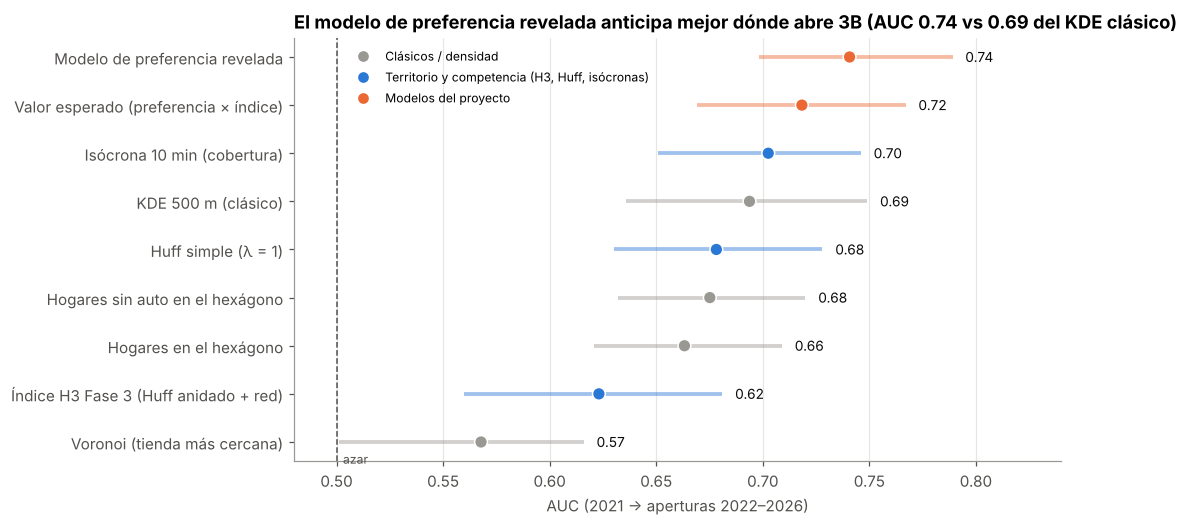

,auc,auc_ic_inf,auc_ic_sup,auc_promedio_folds,captura_10,lift_10,captura_20,auc_vecindad
modelo,,,,,,,,
Modelo de preferencia revelada,0.741,0.698,0.789,0.731,0.261,2.614,0.444,0.752
Valor esperado (preferencia × índice),0.718,0.669,0.767,0.706,0.209,2.092,0.418,0.732
Isócrona 10 min (cobertura),0.703,0.651,0.746,0.686,0.216,2.157,0.412,0.692
KDE 500 m (clásico),0.694,0.636,0.749,0.671,0.170,1.699,0.405,0.715
Huff simple (λ = 1),0.678,0.630,0.728,0.659,0.196,1.961,0.359,0.699
Hogares sin auto en el hexágono,0.675,0.632,0.720,0.654,0.157,1.569,0.333,0.690
Hogares en el hexágono,0.663,0.621,0.709,0.643,0.157,1.569,0.320,0.684
Índice H3 Fase 3 (Huff anidado + red),0.623,0.560,0.681,0.604,0.124,1.242,0.294,0.639
Voronoi (tienda más cercana),0.568,0.501,0.616,0.548,0.144,1.438,0.248,0.575


In [2]:
c = comp.sort_values("auc").reset_index(drop=True)
nuestros = {"Modelo de preferencia revelada", "Valor esperado (preferencia × índice)"}
clasicos = {"KDE 500 m (clásico)", "Voronoi (tienda más cercana)", "Hogares en el hexágono", "Hogares sin auto en el hexágono"}
col = [NARANJA if m in nuestros else GRIS if m in clasicos else AZUL for m in c.modelo]
fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(range(len(c)), c.auc_ic_inf, c.auc_ic_sup, color=col, linewidth=2.5, alpha=0.45)
ax.scatter(c.auc, range(len(c)), color=col, s=70, zorder=3, edgecolor="white", linewidth=1)
for i, v in enumerate(c.auc):
    ax.text(c.auc_ic_sup[i] + 0.006, i, f"{v:.2f}", va="center", fontsize=9, color=TINTA)
ax.axvline(0.5, color=TINTA2, linewidth=1, linestyle="--")
ax.text(0.503, -0.45, "azar", fontsize=8, color=TINTA2)
ax.set_yticks(range(len(c)), c.modelo); ax.grid(axis="y", visible=False)
ax.set_xlim(0.48, 0.84); ax.set_xlabel("AUC (2021 → aperturas 2022–2026)")
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], marker="o", color=k, linestyle="") for k in (GRIS, AZUL, NARANJA)],
          ["Clásicos / densidad", "Territorio y competencia (H3, Huff, isócronas)", "Modelos del proyecto"],
          loc="upper left", bbox_to_anchor=(0.06, 1.0), fontsize=8)
mejor = c.iloc[-1]; kde = c.set_index("modelo").loc["KDE 500 m (clásico)"]
ax.set_title(f"El modelo de preferencia revelada anticipa mejor dónde abre 3B (AUC {mejor.auc:.2f} vs {kde.auc:.2f} del KDE clásico)")
fig.savefig(FIG / "04_comparacion_metodos.png")
plt.show()
comp.set_index("modelo")[["auc", "auc_ic_inf", "auc_ic_sup", "auc_promedio_folds", "captura_10", "lift_10", "captura_20", "auc_vecindad"]].sort_values("auc", ascending=False).round(3)

In [3]:
pd.DataFrame(r["pruebas"]).T.round(3)

,diferencia,ic_inf,ic_sup,p_mejor
Modelo de preferencia revelada vs KDE 500 m (clásico),0.047,0.014,0.083,1.000
Valor esperado (preferencia × índice) vs KDE 500 m (clásico),0.025,-0.008,0.052,0.952
Huff simple (λ = 1) vs Voronoi (tienda más cercana),0.110,0.058,0.180,1.000
Isócrona 10 min (cobertura) vs Voronoi (tienda más cercana),0.135,0.092,0.185,1.000


**Lectura:**
- **Voronoi es el peor**: una frontera rígida "cada hogar va a la tienda más cercana" ignora que la gente camina por calles y que hay competencia de otros formatos.
- **Isócronas por la red de calles** superan claramente a Voronoi y al KDE: la distancia real caminando importa más que la distancia en línea recta.
- **Huff simple** también supera a Voronoi: el modelo probabilístico de competencia es mejor que la regla del más cercano.
- El **índice de la Fase 3** (Huff anidado, que castiga fuerte la canibalización) es el que menos predice entre los modernos: **3B no evita la canibalización, densifica**. Es un hallazgo de negocio, no un error del índice (ver sección 4).
- El **modelo de preferencia revelada** aprende de las aperturas reales qué combinación de variables busca 3B, y le gana al KDE en 100% de los re-muestreos.

## 2. Curva de ganancia: si 3B revisara solo una parte de la ciudad

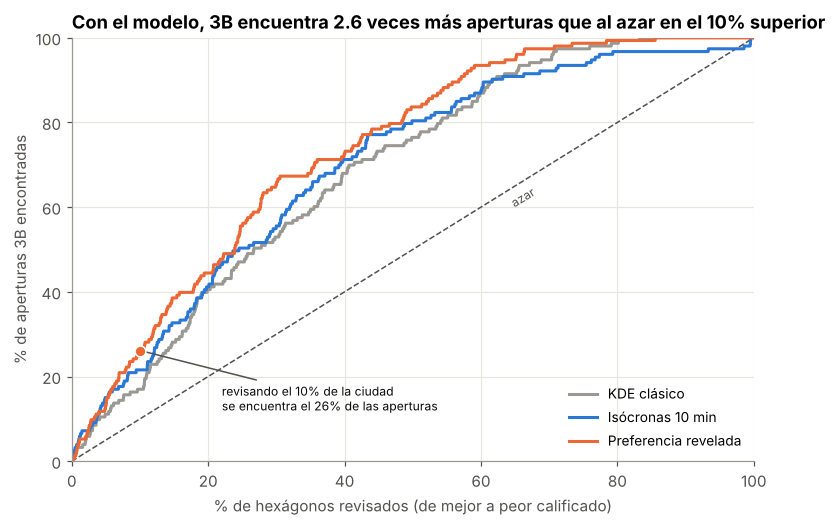

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
series = [("KDE 500 m (clásico)", GRIS, "KDE clásico"), ("Isócrona 10 min (cobertura)", AZUL, "Isócronas 10 min"),
          ("Modelo de preferencia revelada", NARANJA, "Preferencia revelada")]
ax.plot([0, 100], [0, 100], color=TINTA2, linestyle="--", linewidth=1)
ax.text(64, 60, "azar", fontsize=8, color=TINTA2, rotation=31)
for nombre, color, corto in series:
    g = r["ganancia"][nombre]
    ax.plot(100 * g.pct_hexagonos, 100 * g.pct_aperturas, color=color, linewidth=2, label=corto)
p10 = bt.captura_at(u.p_apertura_oob, u.y, 0.10)
ax.scatter([10], [100 * p10], color=NARANJA, s=50, zorder=4, edgecolor="white")
ax.annotate(f"revisando el 10% de la ciudad\nse encuentra el {p10:.0%} de las aperturas", (10, 100 * p10), (22, 12),
            fontsize=8, color=TINTA, arrowprops=dict(arrowstyle="-", color=TINTA2))
ax.set_xlabel("% de hexágonos revisados (de mejor a peor calificado)"); ax.set_ylabel("% de aperturas 3B encontradas")
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.legend(loc="lower right", fontsize=9)
ax.set_title(f"Con el modelo, 3B encuentra {p10 / 0.10:.1f} veces más aperturas que al azar en el 10% superior")
fig.savefig(FIG / "04_curva_ganancia.png")
plt.show()

## 3. ¿Qué busca 3B al abrir? (preferencia revelada)

Regresión logística con variables estandarizadas: cada barra es el efecto de subir una desviación estándar esa variable, manteniendo las demás fijas.
Las líneas negras son el rango del coeficiente entre los 5 folds de la validación cruzada (estabilidad).

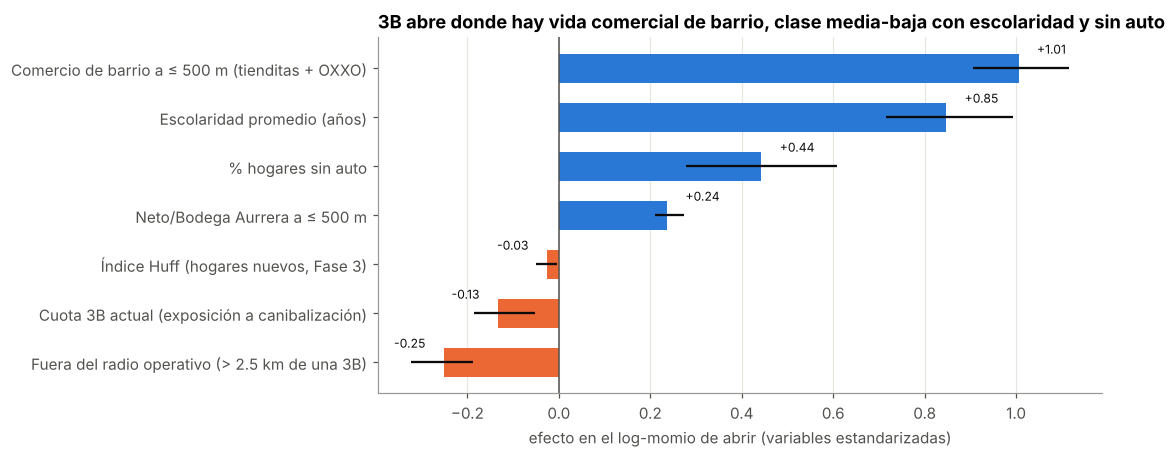

,descripcion,coef,coef_min_fold,coef_max_fold
4,Fuera del radio operativo (> 2.5 km de una 3B),-0.25,-0.32,-0.19
1,Cuota 3B actual (exposición a canibalización),-0.13,-0.19,-0.05
0,"Índice Huff (hogares nuevos, Fase 3)",-0.03,-0.05,-0.00
3,Neto/Bodega Aurrera a ≤ 500 m,0.24,0.21,0.27
5,% hogares sin auto,0.44,0.28,0.61
6,Escolaridad promedio (años),0.85,0.71,0.99
2,Comercio de barrio a ≤ 500 m (tienditas + OXXO),1.01,0.91,1.12


In [5]:
co = r["coeficientes"].sort_values("coef")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(co.descripcion, co.coef, color=[AZUL if v > 0 else NARANJA for v in co.coef], height=0.6)
ax.hlines(range(len(co)), co.coef_min_fold, co.coef_max_fold, color=TINTA, linewidth=1.5)
ax.axvline(0, color=TINTA2, linewidth=1)
for i, v in enumerate(co.coef):
    ax.text(v + (0.04 if v >= 0 else -0.04), i + 0.3, f"{v:+.2f}", ha="left" if v >= 0 else "right", fontsize=8, color=TINTA)
ax.grid(axis="y", visible=False); ax.set_xlabel("efecto en el log-momio de abrir (variables estandarizadas)")
ax.set_title("3B abre donde hay vida comercial de barrio, clase media-baja con escolaridad y sin auto")
fig.savefig(FIG / "04_drivers_apertura.png")
plt.show()
co[["descripcion", "coef", "coef_min_fold", "coef_max_fold"]].round(2)

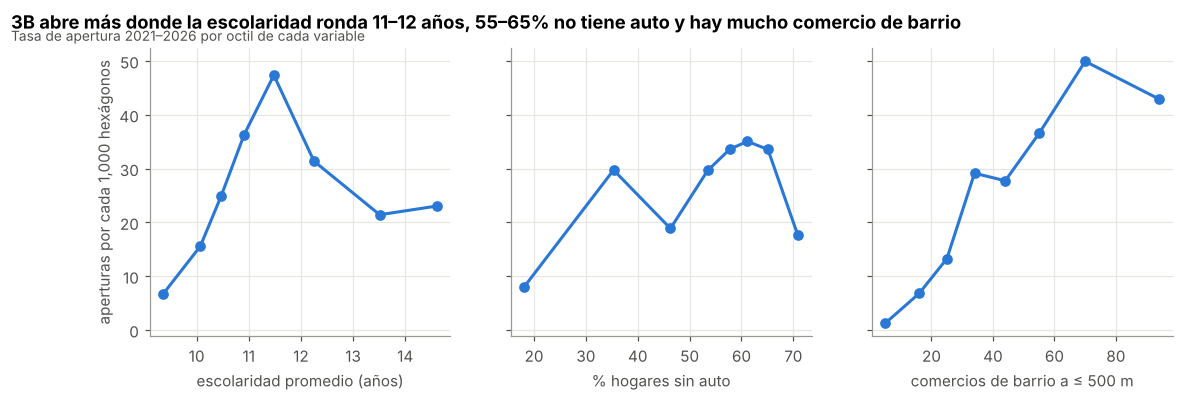

In [6]:
# La relación con escolaridad y % sin auto no es lineal: hay un "punto óptimo" (clase media-baja)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (var, nombre) in zip(axes, [("escolaridad_promedio", "escolaridad promedio (años)"), ("pct_sin_auto", "% hogares sin auto"),
                                    ("comercio_500", "comercios de barrio a ≤ 500 m")]):
    q = pd.qcut(u[var], 8, duplicates="drop")
    t = u.groupby(q, observed=True).agg(x=(var, "median"), tasa=("y", "mean"))
    ax.plot(t.x, 1000 * t.tasa, marker="o", color=AZUL, linewidth=2)
    ax.set_xlabel(nombre)
axes[0].set_ylabel("aperturas por cada 1,000 hexágonos")
fig.suptitle("3B abre más donde la escolaridad ronda 11–12 años, 55–65% no tiene auto y hay mucho comercio de barrio", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.9, "Tasa de apertura 2021–2026 por octil de cada variable", fontsize=9, color=TINTA2)
fig.savefig(FIG / "04_tasa_por_variable.png")
plt.show()

## 4. Calibración del Huff con validación cruzada espacial

Rejilla: λ (nido) ∈ {0.25, 0.5, 0.75, 1}, β (decaimiento) ∈ {200, 350, 500} m, radio de red ∈ {1.5, 2, 2.5, 3 km, sin límite}.
En cada fold se elige la combinación con mejor AUC en los otros bloques y se mide en el bloque que no vio.

AUC fuera de bloque del Huff calibrado: 0.655
Combinación elegida en cada fold: ['(1.0, 200, 1500)', '(1.0, 200, 2000)', '(1.0, 200, 2000)', '(1.0, 350, 2000)', '(1.0, 200, 2000)']


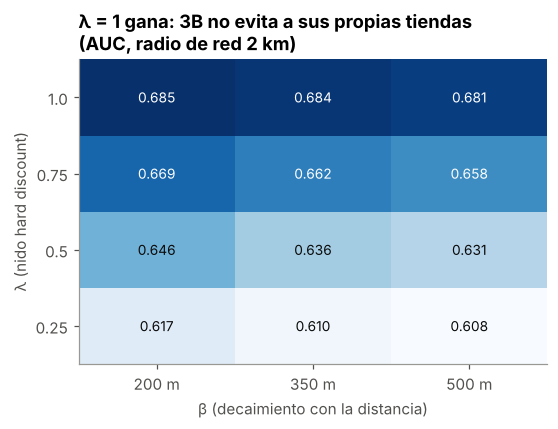

,lambda,beta_m,radio_red_m,auc
46,1.0,200,2000,0.685432
51,1.0,350,2000,0.683569
45,1.0,200,1500,0.682926
47,1.0,200,2500,0.682836
48,1.0,200,3000,0.682498
49,1.0,200,sin límite,0.681524
56,1.0,500,2000,0.681112
50,1.0,350,1500,0.680363
52,1.0,350,2500,0.679639
53,1.0,350,3000,0.679611


In [7]:
cv = r["cv_huff"]
print(f"AUC fuera de bloque del Huff calibrado: {cv['auc_fuera_de_bloque']:.3f}")
print("Combinación elegida en cada fold:", cv["elegidas"])
rej = r["rejilla_huff"]
piv = rej[rej.radio_red_m.astype(str) == "2000"].pivot(index="lambda", columns="beta_m", values="auc")
fig, ax = plt.subplots(figsize=(5.5, 3.6))
im = ax.imshow(piv.values, cmap="Blues", aspect="auto", origin="lower")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9, color="white" if v > piv.values.mean() else TINTA)
ax.set_xticks(range(piv.shape[1]), [f"{b} m" for b in piv.columns]); ax.set_yticks(range(piv.shape[0]), piv.index)
ax.set_xlabel("β (decaimiento con la distancia)"); ax.set_ylabel("λ (nido hard discount)"); ax.grid(False)
ax.set_title("λ = 1 gana: 3B no evita a sus propias tiendas\n(AUC, radio de red 2 km)")
fig.savefig(FIG / "04_calibracion_huff.png")
plt.show()
rej.head(10)

**Decisión:** la calibración elige λ = 1 en los 5 folds. Eso describe **cómo decide 3B** (densifica y acepta canibalizarse), no cuántas ventas pierde una tienda vecina.
Sin datos de ventas no se puede calibrar la canibalización real, así que para **valuar** cada zona se conserva λ = 0.5 (estimación conservadora de hogares nuevos) y para **predecir** se usa el modelo de preferencia revelada.
Con datos internos de 3B (ventas por tienda antes y después de abrir una vecina) se recalibraría λ directamente.

## 5. Voronoi vs isócronas vs Huff: tres formas de dibujar el territorio de una tienda

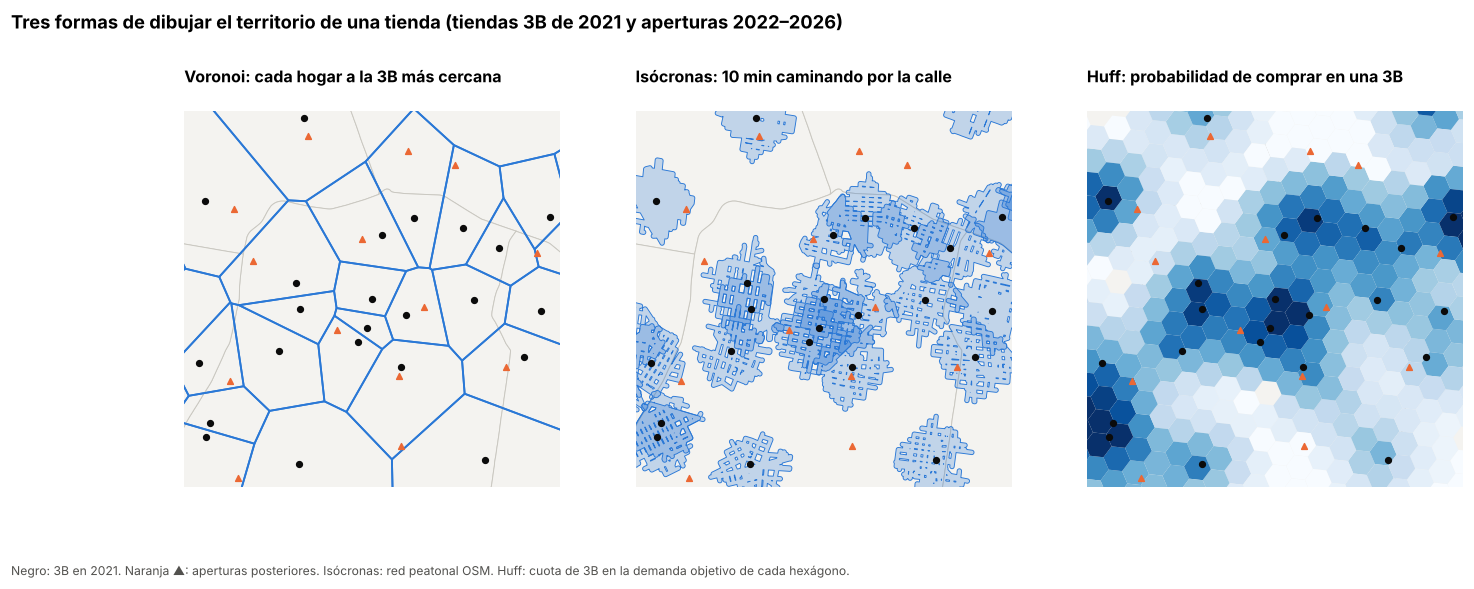

Hogares sin auto con una 3B a ≤ 10 min caminando: 24.4% (2021) -> 41.4% (2026)


In [8]:
est21 = gpd.read_parquet(cfg.SILVER / f"establecimientos_{cfg.CORTE_BACKTEST}.parquet")
t21 = est21[est21.cadena == "3B"].to_crs(cfg.CRS_METRIC)
alc = gpd.read_parquet(cfg.SILVER / "alcaldias.parquet").to_crs(cfg.CRS_METRIC)
limite = gpd.read_parquet(cfg.SILVER / "limite_cdmx.parquet")
ap = r["aperturas"].to_crs(cfg.CRS_METRIC)

# Ventana de 6 km con más tiendas 3B en 2021
xy = np.c_[t21.geometry.x, t21.geometry.y]
mejor = max(range(len(xy)), key=lambda i: (np.abs(xy - xy[i]) < 3000).all(axis=1).sum())
cx, cy = xy[mejor]; W = (cx - 3000, cx + 3000, cy - 3000, cy + 3000)

vor = inf.poligonos_voronoi(est21[est21.cadena == "3B"], limite).to_crs(cfg.CRS_METRIC)
red = inf.RedPeatonal.cargar()
lim = inf.limite_caminando_m(10)
en_w = t21[t21.geometry.x.between(W[0] - 1500, W[1] + 1500) & t21.geometry.y.between(W[2] - 1500, W[3] + 1500)]
if red is not None:
    iso = gpd.GeoSeries([red.isocrona(np.array([p.x, p.y]), lim) for p in en_w.geometry], crs=cfg.CRS_METRIC)
else:
    iso = en_w.geometry.buffer(lim / cfg.FACTOR_RODEO)

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
titulos = ["Voronoi: cada hogar a la 3B más cercana", "Isócronas: 10 min caminando por la calle", "Huff: probabilidad de comprar en una 3B"]
for ax, tit in zip(axes, titulos):
    alc.plot(ax=ax, color="#f4f3f0", edgecolor="#c9c7c0", linewidth=0.6)
    ax.set_xlim(W[0], W[1]); ax.set_ylim(W[2], W[3]); ax.set_axis_off(); ax.set_title(tit, fontsize=10.5)
vor.boundary.plot(ax=axes[0], color=AZUL, linewidth=1.2)
iso.plot(ax=axes[1], color=AZUL, alpha=0.25, linewidth=0)
iso.boundary.plot(ax=axes[1], color=AZUL, linewidth=0.6)
cuota = gpd.read_parquet(cfg.GOLD / f"indice_h3_{cfg.CORTE_BACKTEST}.parquet").to_crs(cfg.CRS_METRIC)
cuota.plot(ax=axes[2], column="cuota_3b_actual", cmap="Blues", vmin=0, vmax=cuota.cuota_3b_actual.quantile(0.98), linewidth=0)
for ax in axes:
    t21.plot(ax=ax, color=TINTA, markersize=14, zorder=4)
    ap.plot(ax=ax, color=NARANJA, markersize=14, marker="^", zorder=4)
fig.suptitle("Tres formas de dibujar el territorio de una tienda (tiendas 3B de 2021 y aperturas 2022–2026)", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.03, f"Negro: 3B en 2021. Naranja ▲: aperturas posteriores. Isócronas: {r['metodo_isocrona']}. "
         f"Huff: cuota de 3B en la demanda objetivo de cada hexágono.", fontsize=8, color=TINTA2)
fig.savefig(FIG / "04_territorios.png")
plt.show()
ci = r["cobertura_iso"]
print(f"Hogares sin auto con una 3B a ≤ 10 min caminando: {ci[cfg.CORTE_BACKTEST]:.1%} (2021) -> {ci[cfg.CORTE_ACTUAL]:.1%} (2026)")

| Método | Supuesto | Fortaleza | Debilidad | AUC backtest |
| --- | --- | --- | --- | --- |
| **Voronoi** | Cada hogar compra en la tienda más cercana (línea recta) | Simple, fronteras claras | Ignora calles, competencia de otros formatos y que los territorios se traslapan | el más bajo |
| **Isócronas** | Atendido si hay tienda a ≤ 10 min caminando por la red | Distancia real; mide cobertura | Binario: dentro/fuera; no reparte clientes entre tiendas | 2.º mejor de los métodos sin aprendizaje |
| **Huff** | Probabilidad que decae con la distancia y crece con el atractivo; todos los formatos compiten | Reparte la demanda, mide canibalización | Requiere supuestos (β, atractivos) que se calibran | intermedio |

## 6. Mapa de aciertos: ¿dónde acertó y dónde falló el modelo?

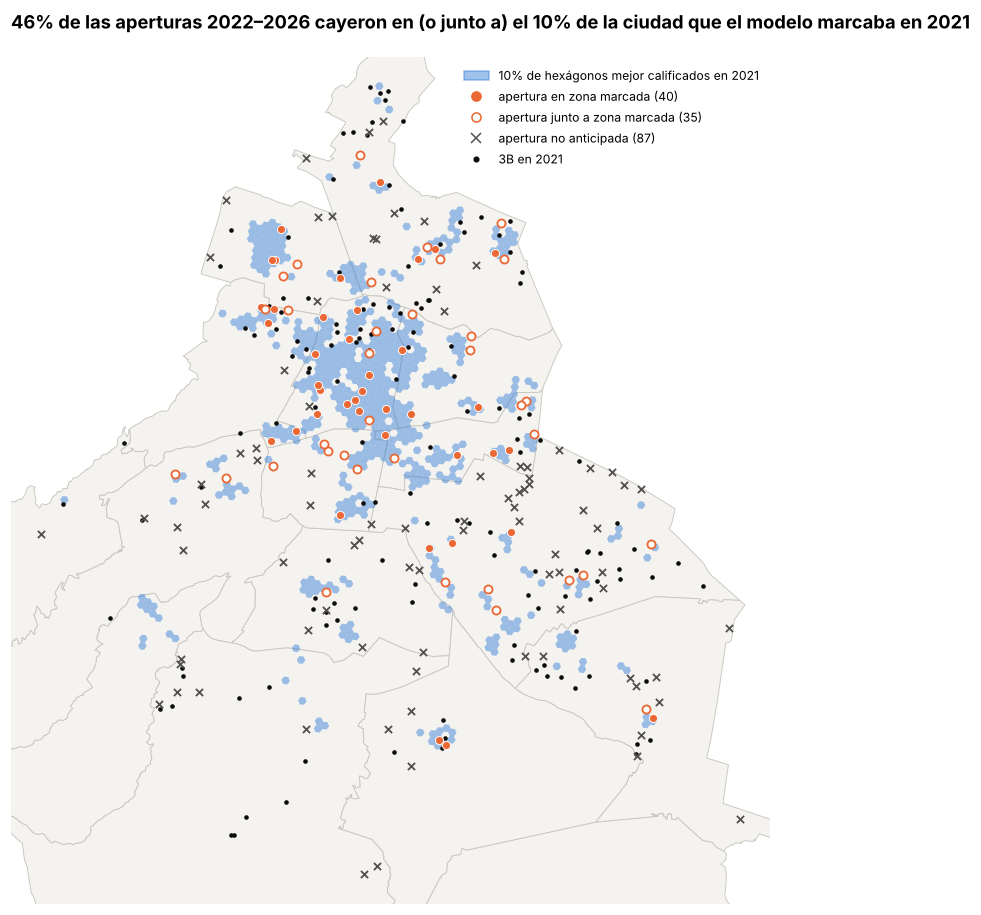

In [9]:
umbral = u.p_apertura_oob.quantile(0.90)
u_g = gpd.GeoDataFrame(u, geometry=u.geometry, crs=cfg.CRS_WEB).to_crs(cfg.CRS_METRIC)
alto = u_g[u_g.p_apertura_oob >= umbral]
ap_h = ap.merge(u[["h3", "p_apertura_oob"]], on="h3", how="left")
ap_h["acierto"] = ap_h.p_apertura_oob >= umbral
vecinos_alto = {v for c in alto.h3 for v in __import__("h3").grid_disk(c, 1)}
ap_h["cerca"] = ~ap_h.acierto & ap_h.h3.isin(vecinos_alto)
n, a, ce = len(ap_h), ap_h.acierto.sum(), ap_h.cerca.sum()

fig, ax = plt.subplots(figsize=(9, 10))
x0, y0, x1, y1 = pd.concat([t21.geometry, ap.geometry]).total_bounds
alc.plot(ax=ax, color="#f4f3f0", edgecolor="#c9c7c0", linewidth=0.6)
alto.plot(ax=ax, color=AZUL, alpha=0.45, linewidth=0)
t21.plot(ax=ax, color=TINTA, markersize=4, zorder=3)
ap_h[ap_h.acierto].plot(ax=ax, color=NARANJA, markersize=28, marker="o", edgecolor="white", linewidth=0.6, zorder=5)
ap_h[ap_h.cerca].plot(ax=ax, color=NARANJA, markersize=28, marker="o", facecolor="white", linewidth=1.2, zorder=5)
ap_h[~ap_h.acierto & ~ap_h.cerca].plot(ax=ax, color=TINTA2, markersize=22, marker="x", linewidth=1.2, zorder=4)
ax.set_xlim(x0 - 1500, x1 + 1500); ax.set_ylim(y0 - 1500, y1 + 1500); ax.set_axis_off()
from matplotlib.patches import Patch
ax.legend([Patch(color=AZUL, alpha=0.45), Line2D([], [], marker="o", color=NARANJA, linestyle=""),
           Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor=NARANJA, linestyle=""),
           Line2D([], [], marker="x", color=TINTA2, linestyle=""), Line2D([], [], marker="o", color=TINTA, markersize=3, linestyle="")],
          ["10% de hexágonos mejor calificados en 2021", f"apertura en zona marcada ({a})", f"apertura junto a zona marcada ({ce})",
           f"apertura no anticipada ({n - a - ce})", "3B en 2021"], loc="upper right", fontsize=8, framealpha=0.9, frameon=True, edgecolor="none")
ax.set_title(f"{(a + ce) / n:.0%} de las aperturas 2022–2026 cayeron en (o junto a) el 10% de la ciudad que el modelo marcaba en 2021")
fig.savefig(FIG / "04_mapa_aciertos.png")
plt.show()

In [10]:
# ¿Cómo son las aperturas que el modelo NO anticipó?
fallos = ap_h[~ap_h.acierto & ~ap_h.cerca].h3
perfil = u.assign(grupo=np.select([u.h3.isin(ap_h[ap_h.acierto].h3), u.h3.isin(fallos)], ["acierto", "no anticipada"], "sin apertura"))
perfil.groupby("grupo")[["hogares", "demanda_objetivo", "comercio_500", "hd_competencia_500", "escolaridad_promedio", "pct_sin_auto", "dist_3b_m"]].median().round(1)

,hogares,demanda_objetivo,comercio_500,hd_competencia_500,escolaridad_promedio,pct_sin_auto,dist_3b_m
grupo,,,,,,,
acierto,654.0,367.5,69.0,2.0,11.9,57.7,814.0
no anticipada,501.0,249.8,53.0,0.0,11.0,58.3,1169.0
sin apertura,372.0,177.6,38.0,0.0,11.2,55.9,1356.0


## 7. Top 20 que se habría recomendado en 2021

Acierto = hubo una apertura 3B confirmada a ≤ 600 m del centro de la zona recomendada. Con 20 zonas los intervalos son anchos (Wilson 95%):
esta es la lectura para negocio; la comparación estadística fina es el AUC de la sección 1.

In [11]:
pd.DataFrame([{"método": n, "aciertos": f"{a['aciertos']}/{a['zonas']}", "precisión": a["precision"],
               "IC 95%": f"{a['ic'][0]:.0%}–{a['ic'][1]:.0%}", "tasa al azar": a["tasa_azar"], "lift": a["lift"]}
              for n, (_, a) in r["tops_2021"].items()]).round(2)

,método,aciertos,precisión,IC 95%,tasa al azar,lift
0,Valor esperado (recomendación),10/20,0.50,30%–70%,0.2,2.49
1,Modelo de preferencia revelada,11/20,0.55,34%–74%,0.2,2.74
2,Índice H3 Fase 3,8/20,0.40,22%–61%,0.2,1.99
3,KDE 500 m,12/20,0.60,39%–78%,0.2,2.99


## 8. Recomendación final: Top 20 para 2026

El modelo de preferencia por sí solo concentra la lista en el centro (Cuauhtémoc, Venustiano Carranza): replica lo que 3B ya hace.
El índice Huff por sí solo mide mercado pero no "parecido a 3B". La **regla final** combina ambos:

> **valor esperado = P(zona tipo 3B) × hogares nuevos (índice Huff)**

En el backtest esta regla conserva un AUC de ~0.72 (mejor que todos los métodos clásicos) y reparte la recomendación entre el centro y las zonas de mayor mercado (Iztapalapa, Álvaro Obregón, Coyoacán).

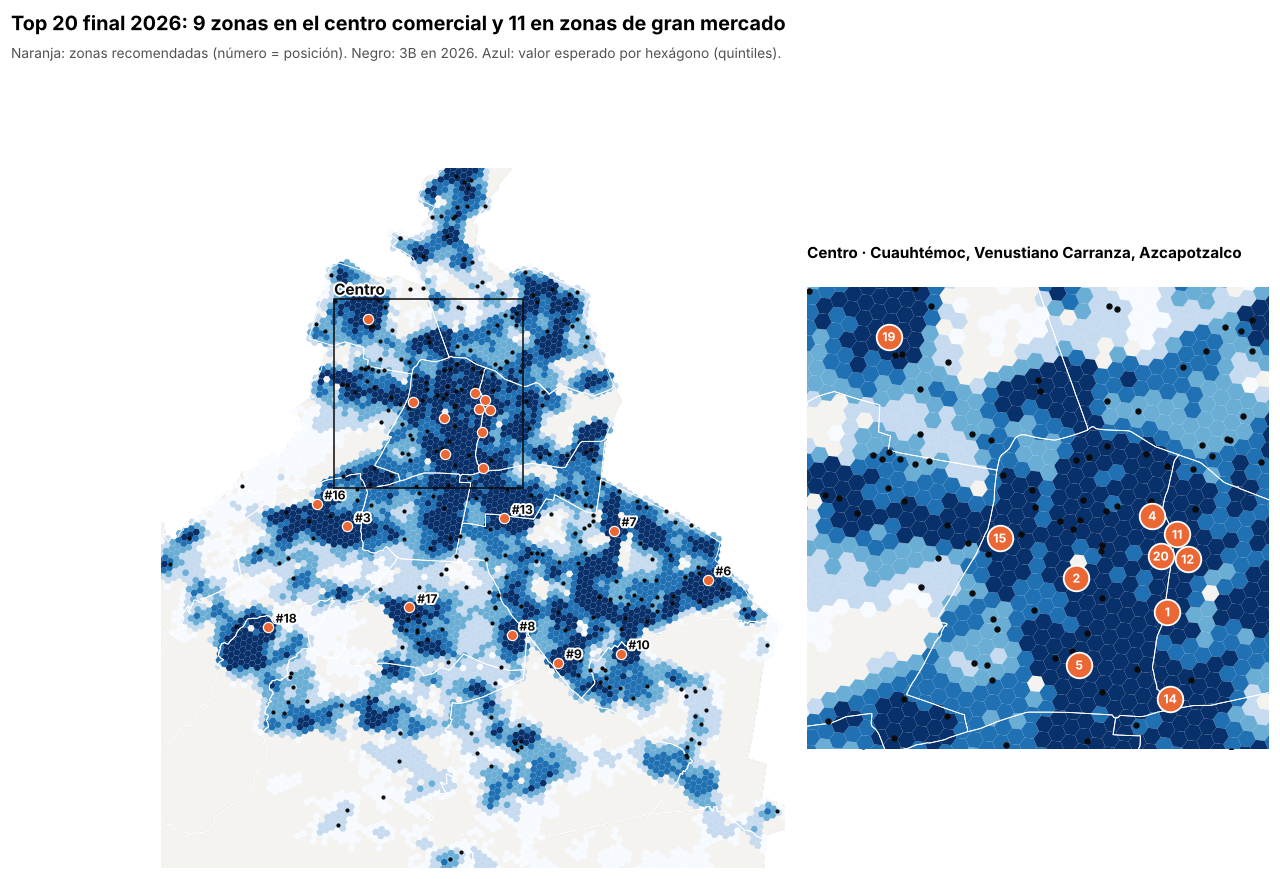

,posicion,h3,alcaldia,valor_esperado,prioridad,p_apertura,indice_final,indice,capturada,canibalizacion,pct_canibalizacion,hogares,hogares_sin_auto,pct_sin_auto,escolaridad_promedio,comercio_500,hd_competencia_500,dist_3b_m
0,1,894995bb177ffff,Venustiano Carranza,44.795,100.0,0.244,183.7,183.7,211.4,27.7,13.1,395.0,352.46,89.23,9.28,307.0,3.0,251.0
1,2,894995b8403ffff,Cuauhtémoc,43.366,100.0,0.267,162.7,162.7,216.6,53.9,24.9,628.0,405.69,64.60,14.76,76.0,1.0,774.0
2,3,89499584b2bffff,Álvaro Obregón,43.267,99.9,0.091,473.4,473.4,490.3,16.9,3.4,588.0,314.83,53.54,11.79,82.0,2.0,1173.0
3,4,894995b8633ffff,Cuauhtémoc,41.511,99.9,0.141,294.5,294.5,360.9,66.4,18.4,1090.0,915.01,83.95,9.79,154.0,3.0,363.0
4,5,894995ba273ffff,Cuauhtémoc,35.162,99.9,0.144,244.3,244.3,325.9,81.6,25.0,876.0,619.00,70.66,11.82,113.0,2.0,248.0
5,6,8949958c0d3ffff,Iztapalapa,34.498,99.8,0.095,362.3,362.3,420.6,58.4,13.9,744.0,505.93,68.00,9.51,159.0,3.0,638.0
6,7,8949958ea2fffff,Iztapalapa,34.456,99.8,0.042,811.1,811.1,835.0,23.9,2.9,1206.0,900.00,74.63,9.92,104.0,0.0,1314.0
7,8,894995853b7ffff,Coyoacán,33.172,99.8,0.057,580.6,580.6,602.3,21.7,3.6,1227.0,829.52,67.61,10.17,97.0,1.0,1341.0
8,9,894995852bbffff,Iztapalapa,32.983,99.7,0.060,547.3,547.3,562.4,15.1,2.7,1358.0,960.68,70.74,9.70,118.0,1.0,1273.0
9,10,8949958e1c3ffff,Tláhuac,32.304,99.7,0.075,431.6,431.6,525.2,93.6,17.8,1144.0,690.58,60.37,11.49,90.0,1.0,839.0


In [12]:
top = r["top_2026"].to_crs(cfg.CRS_METRIC).reset_index(drop=True)
t26 = gpd.GeoDataFrame(r["tabla_2026"], geometry="geometry", crs=cfg.CRS_WEB).to_crs(cfg.CRS_METRIC)
est26 = gpd.read_parquet(cfg.SILVER / f"establecimientos_{cfg.CORTE_ACTUAL}.parquet")
t3b26 = est26[est26.cadena == "3B"].to_crs(cfg.CRS_METRIC)
c = top.geometry.centroid

fig = plt.figure(figsize=(13, 9.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1], wspace=0.04)
ax, az = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
x0, y0, x1, y1 = pd.concat([t3b26.geometry, c]).total_bounds
centro = c[top.alcaldia.isin(["Cuauhtémoc", "Venustiano Carranza", "Azcapotzalco", "Miguel Hidalgo"])]
bx0, by0, bx1, by1 = centro.total_bounds
lado = max(bx1 - bx0, by1 - by0) / 2 + 1200
ZC = ((bx0 + bx1) / 2 - lado, (bx0 + bx1) / 2 + lado, (by0 + by1) / 2 - lado, (by0 + by1) / 2 + lado)
for a, ext in [(ax, (x0 - 500, x1 + 500, y0 - 500, y1 + 500)), (az, ZC)]:
    alc.plot(ax=a, color="#f4f3f0", edgecolor="#c9c7c0", linewidth=0.6)
    t26.plot(ax=a, column="valor_esperado", cmap="Blues", scheme="quantiles", k=5, linewidth=0)
    alc.boundary.plot(ax=a, color="white", linewidth=0.6)
    t3b26.plot(ax=a, color=TINTA, markersize=3 if a is ax else 10, zorder=3)
    a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3]); a.set_axis_off()
en_zoom = c.x.between(ZC[0], ZC[1]) & c.y.between(ZC[2], ZC[3])
ax.scatter(c.x, c.y, s=45, color=NARANJA, edgecolor="white", linewidth=0.8, zorder=4)
for i in np.flatnonzero(~en_zoom.values):
    ax.text(c.x[i] + 450, c.y[i] + 250, f"#{top.posicion[i]}", fontsize=8, fontweight="bold", color=TINTA, path_effects=HALO, zorder=5)
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((ZC[0], ZC[2]), ZC[1] - ZC[0], ZC[3] - ZC[2], fill=False, edgecolor=TINTA, linewidth=1, zorder=6))
ax.text(ZC[0], ZC[3] + 250, "Centro", fontsize=10, fontweight="bold", color=TINTA, path_effects=HALO)
az.scatter(c.x[en_zoom], c.y[en_zoom], s=280, color=NARANJA, edgecolor="white", linewidth=1.2, zorder=4)
for i in np.flatnonzero(en_zoom.values):
    az.text(c.x[i], c.y[i], str(top.posicion[i]), ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=5)
for sp in az.spines.values():
    sp.set_visible(True); sp.set_edgecolor(TINTA)
az.set_title("Centro · " + ", ".join(top.alcaldia[en_zoom].value_counts().index), fontsize=10)
vc = top.alcaldia.value_counts()
fig.suptitle(f"Top 20 final 2026: {vc.get('Cuauhtémoc', 0) + vc.get('Venustiano Carranza', 0)} zonas en el centro comercial "
             f"y {len(top) - vc.get('Cuauhtémoc', 0) - vc.get('Venustiano Carranza', 0)} en zonas de gran mercado", x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.text(0.02, 0.935, "Naranja: zonas recomendadas (número = posición). Negro: 3B en 2026. Azul: valor esperado por hexágono (quintiles).",
         fontsize=9, color=TINTA2)
fig.savefig(FIG / "04_top20_final.png")
plt.show()
top[bt.COLUMNAS_TOP_FINAL[:-2]].round(3)

## 9. Lectura para negocio

| Hallazgo | Implicación para 3B |
| --- | --- |
| El modelo, construido solo con datos de 2021, encuentra **~2.6 veces más aperturas que el azar** en el 10% superior de la ciudad | La herramienta reduce la búsqueda de locales a una fracción de la ciudad sin perder la mayoría de las oportunidades |
| Le gana al KDE clásico con diferencia significativa (bootstrap pareado por bloques) | Un mapa de calor de población no basta: importan la vida comercial, el perfil y la red |
| **Comercio de barrio** es el factor que más pesa | 3B busca calles con flujo peatonal (tienditas, OXXO): ahí está su cliente de compra diaria |
| Clase media-baja **con escolaridad** y sin auto | El cliente 3B no es el más pobre: es el que compara precios y compra a pie |
| Le gusta estar **cerca de Neto y Bodega Aurrera** | Compite de frente en los mismos corredores, no huye de la competencia |
| λ = 1 gana la calibración | 3B acepta canibalizarse para densificar zonas; la canibalización real debe medirse con sus ventas |
| Isócronas por la red > Voronoi | El territorio de una tienda se dibuja con calles reales, no con líneas rectas |
| Cobertura a 10 min caminando: 24% → 41% de los hogares sin auto | Aún hay ~60% del cliente objetivo sin una 3B a 10 minutos |

**Siguiente paso (Fase 5):** la app (Streamlit + pydeck) con el mapa de prioridad, el Top 20, fichas por zona y la descarga del GeoJSON.